# Лабораторная работа 04. Визуализация данных, BI и Data Story

**Курс:** «Анализ данных и искусственный интеллект», 1 курс бакалавриата.

Задача: создать сервис продажи подержанных автомобилей.
Мы получили данные и провели сводный анализ. Теперь используем графики, чтобы:
- __Исследовать данные__: увидеть сложные закономерности, распределения, различия между сегментами и возможные ошибки.
- __Представить результаты__: показать основные выводы и объяснить, как эти данные могут помочь

## 1. Гипотезы для проверки

| Вопрос | Показатель | График | Для чего сервису |
|---|---|---|---|
| Какие марки представлены? | Число и доля записей | Столбцы | Определить охват каталога |
| Какие цены типичны? | Медиана и Q1–Q3 | Boxplot | Получить ценовые ориентиры |
| Как различается состав топлива? | Доли внутри марки | Тепловая карта | Сравнивать сегменты |
| Где возможны ошибки? | Необычные значения и сочетания | Гистограмма, scatter | Проверить качество данных |

**Границы выводов:** данные описывают предложения автомобилей. Для оценки спроса, продаж и выручки нужны сведения о сделках.

## Упражнение
1. Выдвините гипотезы анализа данных, которые вы бы хотели проверить

## 2. Загрузка и подготовка

Положите `cars_processed.csv` рядом с ноутбуком. После лабораторной 03 можно использовать `cars_summary_input.csv`. Для диагностики необработанных данных дополнительно пригодится `cars.csv`. Цены — в евро, пробег — в километрах. Установка при необходимости: `pip install pandas numpy matplotlib seaborn plotly ipywidgets`. Перезапустите ядро после установки.


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 200

In [2]:
from matplotlib.patches import Patch

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

In [4]:
# Положите CSV рядом с ноутбуком. Для примера из репозитория — резервный адрес.
DATA_FILE = ('cars_summary_input.csv' if Path('cars_summary_input.csv').exists()
             else 'cars_processed.csv')
data_path = Path(DATA_FILE)
if data_path.exists():
    df = pd.read_csv(data_path)
else:
    df = pd.read_csv(
        'https://raw.githubusercontent.com/MVRonkin/BasicDataAnalysisCourse/'
        'refs/heads/main/Workshops/cars_processed.csv'
    )

# Совместимость с результатом предыдущей практики.
df = df.rename(columns={'Price(euro)': 'Price', 'Engine_capacity(cm3)': 'Engine'})
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed:')])
if 'Transmission' not in df:
    df['Transmission'] = df['AutoTransmission'].map({True: 'Automatic', False: 'Manual'})
if 'km_year_cat' not in df:
    df['km_year_cat'] = pd.cut(
        df['km_year'], bins=[-np.inf, 10_000, 30_000, np.inf],
        labels=['Small', 'Medium', 'Large']
    )
# Номер строки нужен для возврата от графика к исходной записи; это не ID объявления.
if 'row_id' not in df:
    df['row_id'] = np.arange(len(df))
num_columns = ['Year', 'Distance', 'Engine', 'Price', 'km_year']
cat_columns = ['Make', 'Model', 'Style', 'Fuel_type', 'Transmission', 'km_year_cat']
df.head()


,Year,Distance,Engine,Price,km_year,Make,Model,Style,Fuel_type,Transmission,Style_group,km_year_cat,row_id
0,2011,195000.0,1800.0,7750.0,17727.272727,Toyota,Prius,Hatchback,Hybrid,Automatic,Hatchback,Medium,0
1,2014,135000.0,1500.0,8550.0,16875.000000,Renault,Grand Scenic,Universal,Diesel,Manual,Universal,Medium,1
2,2012,110000.0,1500.0,6550.0,11000.000000,Renault,Laguna,Universal,Diesel,Manual,Universal,Medium,2
3,2006,200000.0,1600.0,4100.0,12500.000000,Opel,Astra,Universal,Metan/Propan,Manual,Universal,Medium,3
4,2000,300000.0,2200.0,3490.0,13636.363636,Mercedes,Vito,Microvan,Diesel,Manual,Microvan,Medium,4


In [5]:
df_base = df.copy()
print(f'Записей: {len(df):,}; марок: {df["Make"].nunique()}')


Записей: 32,066; марок: 22


## 3. Matplotlib: читаемый график для заказчика

### Из Pandas в Matplotlib


__Matplotlib__ — предоставляет широкий спектр возможностей для создания статических графиков. Она обладает гибким API, позволяющим настраивать практически каждый аспект графика. Matplotlib поддерживает различные типы графиков, включая линейные графики, гистограммы, диаграммы рассеяния, столбчатые диаграммы, круговые диаграммы и многое другое. Основные преимущества [Matplotlib включают](https://external.software/archives/18540):
* Широкий спектр поддерживаемых типов графиков.
* Гибкость настройки внешнего вида графиков.
* Возможность создания публикаций высокого качества.
* Интеграция с другими библиотеками Python, такими как NumPy и Pandas.


`matplotlib.pyplot` (обычно `plt`) — интерфейс Matplotlib. `Figure` — весь рисунок; `Axes` — область одного графика. `fig, ax = plt.subplots()` позволяет отдельно настраивать рисунок и оси.

Сначала вернемся к графику из прошлого занятия

In [9]:
make = 'Mercedes'
prices = df[df['Make'] == make].groupby('Year')['Price'].mean()

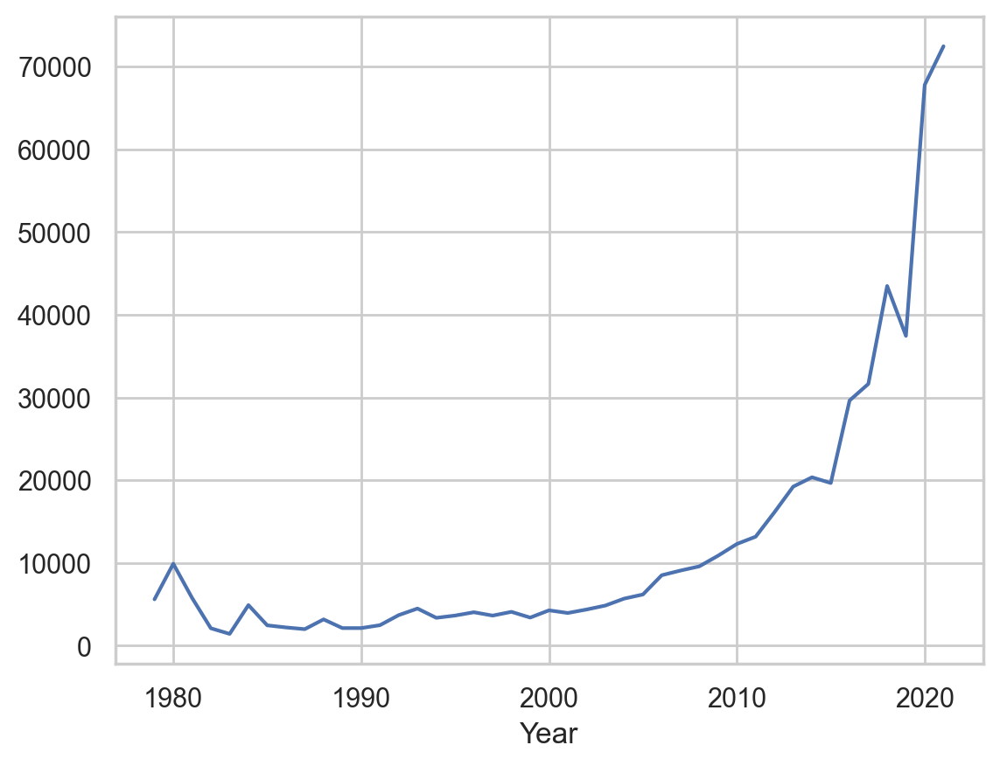

In [10]:
prices.plot(); plt.show()

Теперь в `Matplotlib`

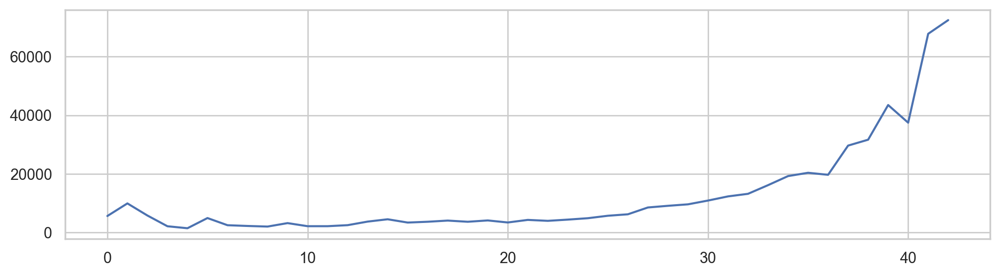

In [11]:
plt.figure(figsize=(12, 3))
plt.plot( prices.values, )
plt.show()

Теперь настроим наш график так, как нам нужно

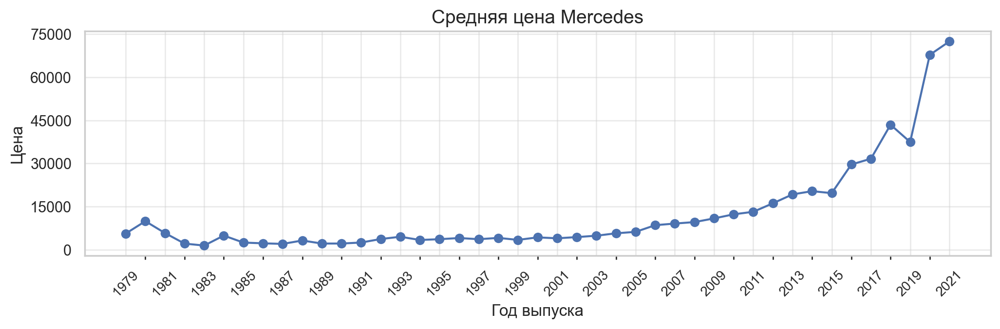

In [13]:
plt.figure(figsize=(12, 3))
ax = plt.gca()
plt.plot(prices.index, prices.values, 'o-', linewidth=1.5)
start, end = int(prices.index.min()), int(prices.index.max())
ax.set_xticks(range(start, end + 1, 2))
ax.set_xticks(range(start + 1, end + 1, 2), minor=True)
ax.tick_params(axis='x', which='minor', bottom=True, length=3)
ax.tick_params(axis='x', which='major', labelsize=10, rotation=45)

ax.set_yticks(np.linspace(0, 5000*(prices.max()//5000+1), 6))  
# ax.set_yticks(np.linspace(0, 5000*(prices.max()//5000+1), 11), 
              # minor=True)  

plt.title(f'Средняя цена {make}', fontsize=14)
plt.xlabel('Год выпуска')
plt.ylabel('Цена')
plt.grid(alpha=0.4)
plt.savefig('fig1.pdf', bbox_inches='tight')
plt.show()

Также хотелось на графике бы видеть разброс цен и количество А/М от года.

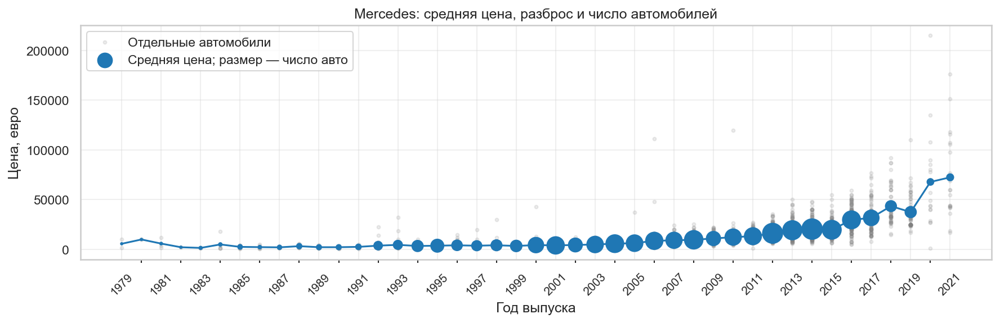

In [15]:
make = 'Mercedes'
cars = df[df['Make'] == make]
stats = cars.groupby('Year')['Price'].agg(['mean', 'count'])

fig, ax = plt.subplots(figsize=(12, 4), dpi=150)

# Отдельные автомобили
ax.scatter(cars['Year'], cars['Price'],
           s=8, alpha=.15, color='gray', label='Отдельные автомобили')

# Средняя цена; площадь кружка пропорциональна числу автомобилей
ax.plot(stats.index, stats['mean'], color='tab:blue', linewidth=1.5)
ax.scatter(stats.index, stats['mean'],
           s=300 * stats['count'] / stats['count'].max(),
           color='tab:blue', label='Средняя цена; размер — число авто')

# # Точное число автомобилей
# for year, row in stats.iterrows():
#     ax.annotate(f'{int(row["count"])}', (year, row['mean']),
#                 xytext=(0, 8), textcoords='offset points',
#                 ha='center', fontsize=8, rotation=45)

start, end = int(stats.index.min()), int(stats.index.max())
ax.set_xticks(range(start, end + 1, 2))
ax.set_xticks(range(start + 1, end + 1, 2), minor=True)
ax.tick_params(axis='x', which='minor', bottom=True, length=3)
ax.tick_params(axis='x', which='major', labelsize=10, rotation=45)

ax.set_title(f'{make}: средняя цена, разброс и число автомобилей')
ax.set_xlabel('Год выпуска')
ax.set_ylabel('Цена, евро')
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
plt.savefig('fig1.pdf', bbox_inches='tight')
plt.show()

## Другие графики

https://matplotlib.org/stable/gallery/index.html

Покажем обычную диаграмму количества записей по маркам, затем сделаем её удобнее: оставим топ-10, упорядочим значения, используем горизонтальные столбцы и добавим доли.

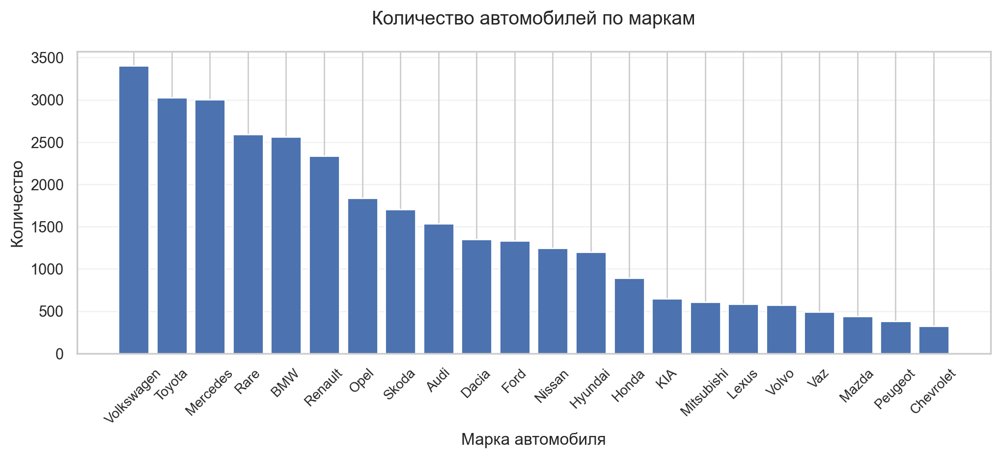

In [16]:
# Создание фигуры 
plt.figure(figsize=(12, 4))

# Создание barchat
data = df['Make'].value_counts()

plt.bar(data.index, data.values)

# Добавляем заголовки и подписи
plt.title('Количество автомобилей по маркам', fontsize=14, pad=20)
plt.xlabel('Марка автомобиля', fontsize=12)
plt.ylabel('Количество', fontsize=12)

plt.grid(axis='y', alpha=0.25)

# делаем ось X красивой
plt.tick_params(axis='x', rotation=45, labelsize=10)


plt.show()


Если подписей слишком много, график плохо читается. 

Попробуем сделать более инфромативный график

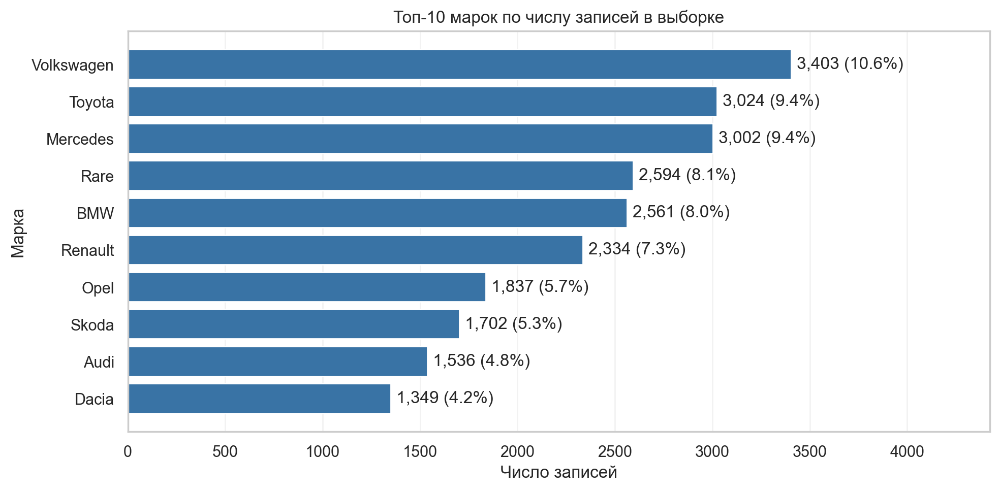

Остальные марки: 8,724 записей


In [17]:
counts = df['Make'].value_counts()
top = counts.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top.index, top.values, color='#3973a5')
ax.bar_label(bars, labels=[f'{n:,} ({100*n/len(df):.1f}%)' for n in top], padding=4)
ax.set(title='Топ-10 марок по числу записей в выборке',
       xlabel='Число записей', ylabel='Марка')
ax.set_xlim(0, top.max() * 1.3)
ax.grid(axis='x', alpha=.25)
ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()
print(f'Остальные марки: {len(df) - counts.head(10).sum():,} записей')




### Каталог: настройка цвета, сетки и подписей


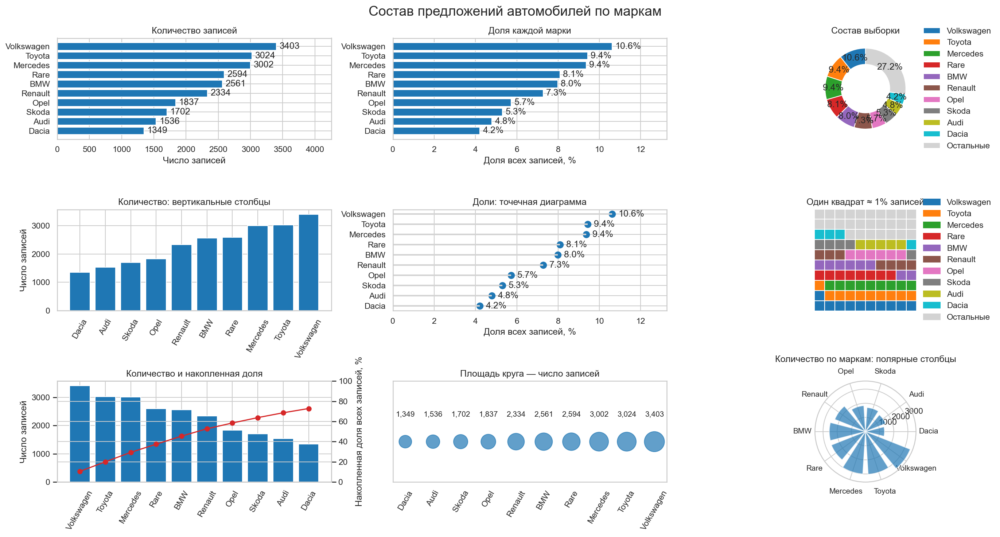

In [19]:
counts = df['Make'].value_counts()
top = counts.head(10).sort_values()
share = 100 * top / len(df)

parts = counts.head(10).copy()
parts['Остальные'] = len(df) - parts.sum()
colors = list(plt.cm.tab10.colors[:len(parts) - 1]) + ['lightgray']

fig, axes = plt.subplots(3, 3, figsize=(19, 10), dpi=150)
fig.suptitle('Состав предложений автомобилей по маркам', fontsize=18)

# 1. Горизонтальные столбцы: количество
ax = axes[0, 0]
bars = ax.barh(top.index, top.values, color='tab:blue')
ax.bar_label(bars, padding=4)
ax.set(title='Количество записей', xlabel='Число записей')
ax.set_xlim(0, top.max() * 1.25)

# 2. Горизонтальные столбцы: доля
ax = axes[0, 1]
bars = ax.barh(top.index, share.values, color='tab:blue')
ax.bar_label(bars, fmt='%.1f%%', padding=4)
ax.set(title='Доля каждой марки', xlabel='Доля всех записей, %')
ax.set_xlim(0, share.max() * 1.25)

# 3. Кольцевая диаграмма
ax = axes[0, 2]
ax.pie(
    parts.values, colors=colors, startangle=90,
    autopct='%1.1f%%', pctdistance=.8,
    wedgeprops={'width': .4, 'edgecolor': 'white'}
)
ax.set_title('Состав выборки')
ax.legend(parts.index, loc='center left',
          bbox_to_anchor=(1, .5), frameon=False)

# 4. Вертикальные столбцы
ax = axes[1, 0]
ax.bar(top.index, top.values, color='tab:blue')
ax.set(title='Количество: вертикальные столбцы', ylabel='Число записей')
ax.tick_params(axis='x', rotation=60)

# 5. Точечная диаграмма
ax = axes[1, 1]
ax.hlines(top.index, 0, share.values, color='lightgray', linewidth=2)
ax.scatter(share.values, top.index, color='tab:blue', s=70)
for name, value in share.items():
    ax.text(value + .3, name, f'{value:.1f}%', va='center')
ax.set(title='Доли: точечная диаграмма',
       xlabel='Доля всех записей, %', xlim=(0, share.max() * 1.25))

# 6. Мозаика из 100 квадратов
ax = axes[1, 2]
quota = 100 * parts / parts.sum()
squares = np.floor(quota).astype(int)
remainder = 100 - squares.sum()
squares.iloc[np.argsort(-(quota - squares).values)[:remainder]] += 1

cell_colors = np.repeat(np.array(colors, dtype=object), squares.values)
x, y = np.meshgrid(np.arange(10), np.arange(10))
ax.scatter(x.ravel(), y.ravel(), c=cell_colors,
           marker='s', s=180, edgecolors='white')
ax.set(title='Один квадрат ≈ 1% записей', aspect='equal')
ax.axis('off')
ax.legend(
    handles=[Patch(color=c, label=name) for name, c in zip(parts.index, colors)],
    loc='center left', bbox_to_anchor=(1, .5), frameon=False
)

# 7. Парето: количество и накопленная доля
ax = axes[2, 0]
ranked = counts.head(10)
ax.bar(ranked.index, ranked.values, color='tab:blue')
ax.set(title='Количество и накопленная доля', ylabel='Число записей')
ax.tick_params(axis='x', rotation=60)

ax_share = ax.twinx()
ax_share.plot(ranked.index, 100 * ranked.cumsum() / len(df),
              'o-', color='tab:red')
ax_share.set(ylabel='Накопленная доля всех записей, %', ylim=(0, 100))

# 8. Пузыри: площадь круга соответствует количеству
ax = axes[2, 1]
positions = np.arange(len(top))
ax.scatter(positions, np.zeros(len(top)),
           s=700 * top.values / top.max(), color='tab:blue', alpha=.7)
for x, n in zip(positions, top.values):
    ax.text(x, .25, f'{n:,}', ha='center', fontsize=10)
ax.set_xticks(positions, top.index, rotation=60)
ax.set(title='Площадь круга — число записей', ylim=(-.4, .6))
ax.set_yticks([])
ax.grid(False)

# 9. Полярные столбцы: длина соответствует количеству
axes[2, 2].remove()
ax = fig.add_subplot(3, 3, 9, projection='polar')
angles = np.linspace(0, 2 * np.pi, len(top), endpoint=False)
ax.bar(angles, top.values, width=2*np.pi/len(top)*.8,
       color='tab:blue', alpha=.7)
ax.set_xticks(angles, top.index, fontsize=10)
ax.set_title('Количество по маркам: полярные столбцы', pad=25)


fig.tight_layout()
plt.savefig('brands_comparison.pdf', bbox_inches='tight')
plt.show()

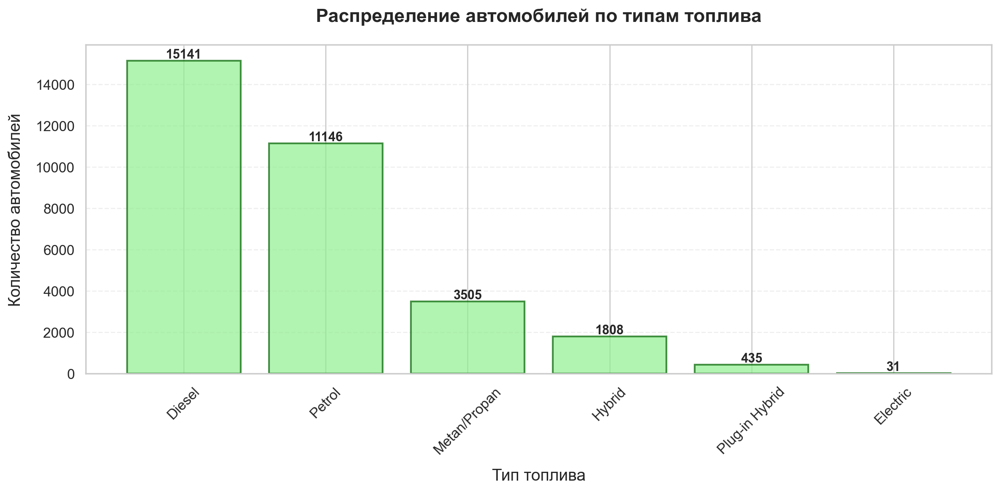

In [18]:
# Создаем фигуру и оси с указанием размера
plt.figure(figsize=(12, 6))

# Получаем количество автомобилей по типам топлива
# value_counts() автоматически сортирует по убыванию частоты
data = df['Fuel_type'].value_counts()

# Создаем столбчатую диаграмму с настройкой внешнего вида
bars = plt.bar(data.index, data.values, 
               color='lightgreen',      # Основной цвет столбцов
               edgecolor='darkgreen',   # Цвет границ столбцов
               alpha=0.7,               # Прозрачность (0-1)
               linewidth=1.5)           # Толщина границ

# НАСТРОЙКА ВНЕШНЕГО ВИДА ОСЕЙ:
# Поворачиваем подписи по оси X для лучшей читаемости
plt.tick_params(axis='x', rotation=45, labelsize=12)
# Настраиваем подписи по оси Y
plt.tick_params(axis='y', labelsize=12)

# ДОБАВЛЯЕМ ПОДПИСИ НАД СТОЛБЦАМИ:
# Проходим по каждому столбцу и добавляем текстовую метку
for bar in bars:
    height = bar.get_height()                    # Получаем высоту столбца
    plt.text(bar.get_x() + bar.get_width()/2.,   # Позиция X (центр столбца)
             height + 0.1,                       # Позиция Y (немного выше столбца)
             f'{int(height)}',                   # Текст (целое число)
             ha='center', va='bottom',           # Выравнивание по центру и снизу
             fontsize=11, fontweight='bold')     # Стиль шрифта

# ЗАГОЛОВКИ И ПОДПИСИ ОСЕЙ:
plt.title('Распределение автомобилей по типам топлива', 
          fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Тип топлива', fontsize=14, labelpad=10)
plt.ylabel('Количество автомобилей', fontsize=14, labelpad=10)

# ДОБАВЛЯЕМ СЕТКУ ДЛЯ ЛУЧШЕЙ ЧИТАЕМОСТИ:
plt.grid(axis='y',    # Сетка только по вертикали (ось Y)
         alpha=0.3,   # Прозрачность сетки
         linestyle='--')  # Стиль линии (пунктир)

# АВТОМАТИЧЕСКИ НАСТРАИВАЕМ ОТСТУПЫ ДЛЯ КРАСИВОГО ОТОБРАЖЕНИЯ
plt.tight_layout()

# ОТОБРАЖАЕМ ГРАФИК
plt.show()

### **Упражнения:** 
1. Выбирите лучший вариант. Постройте визуализации для остальных категориальных переменных.

2. Обычно вывод по категориальным данным - какие категории редкие. Сделайте вывод, приведите категории.


## 4. Распределения численных данных

Когда мы рассматриваем  большие данные, мы предполагаем, что в них есть случайная составляющая, то есть они имеют **стохастическую природу**. Например, разные пользователи нашей платформы могут установить разные цены на один и тот же автомобиль. Другими словами возможны т.н. **флуктуации величины** — случайные колебания значений величины.

Для отдельной записи сложно отделить случайные колебания от закономерностей. Поэтому полезно анализировать записи группами: смотреть, какие значения встречаются чаще, где находится средний уровень и насколько велик разброс или другие т.н. __статистические моменты__.


Оценка групп записей сопостовима с понятием __распределение случайной величины__.

Если взять диапозон значений случайной величины и разделить его на какие-то интервалы, то можно оценить вероятность попадания величины в заданный интервал. 

Диапазон значений выборки случайной величины можно разделить на непересекающиеся интервалы и подсчитать число записей в каждом из них. Такая форма представления называется  - **Гистограмма**. 

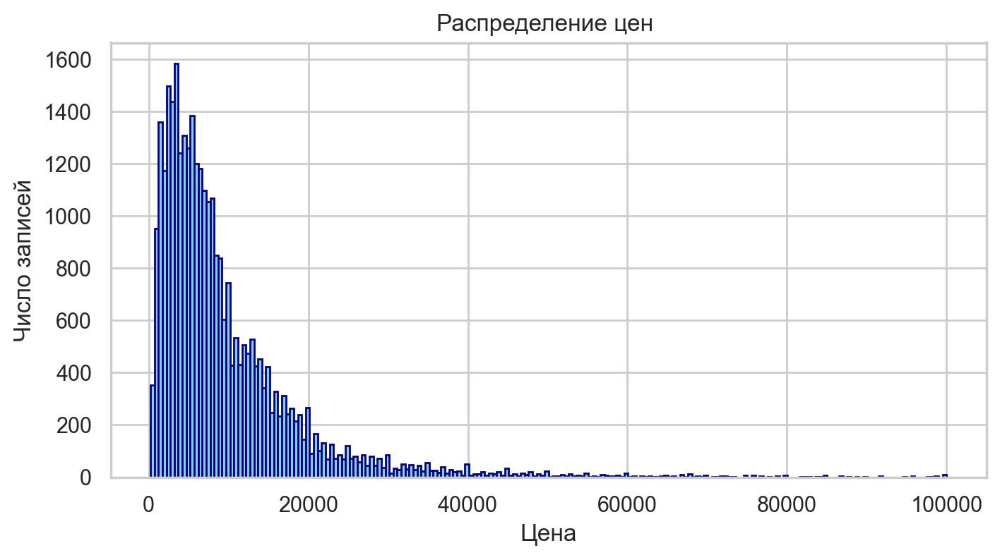

In [21]:
plt.figure(figsize=(8, 4))
plt.hist(df.loc[df['Price'].between(0, 100_000), 'Price'],
         bins=200, color='skyblue', edgecolor='navy')
plt.title('Распределение цен ')
plt.xlabel('Цена')
plt.ylabel('Число записей')
plt.show()

Гистограмма характеризует __распределение случайной величины__.  

__Гистограмма__ помогает увидеть:
- где сосредоточено большинство значений;
- найти моду и медианну значений;
- насколько боьлшой разброс;
- есть ли несколько пиков (моды), есть ли длинный хвост или редкие крайние значения  (выбросы/аномалии)
- Динамика переменной (видно например через асиметрию распределения);
то есть характеризовать т.н. __"распределение"__ в данных.

Интервалы гистограммы называются `bins`. Выбор числа интервалов влияет на вид распределения: слишком мало интервалов скрывает детали, слишком много затрудняет восприятие.


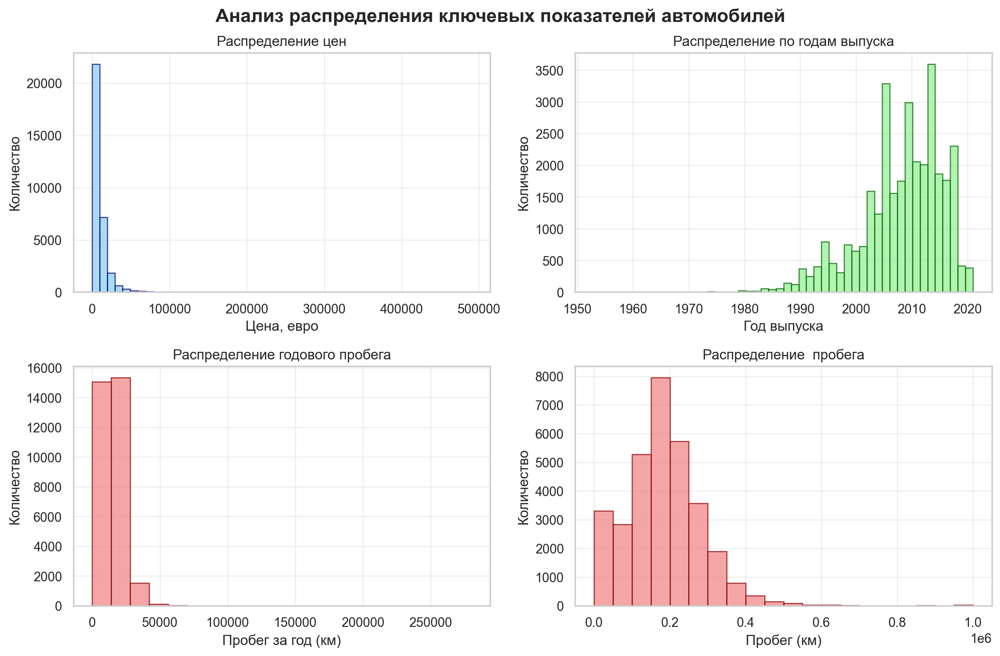

In [22]:
# Создаем фигуру с несколькими subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Анализ распределения ключевых показателей автомобилей', 
             fontsize=16, fontweight='bold', y=0.97)

# Гистограмма цен
axes[0,0].hist(df['Price'], bins=50, color='skyblue', edgecolor='navy', alpha=0.7)
axes[0,0].set_title('Распределение цен')
axes[0,0].set_xlabel('Цена, евро')
axes[0,0].set_ylabel('Количество')
axes[0,0].grid(alpha=0.3)

# Гистограмма годов
axes[0,1].hist(df['Year'], bins=50, color='lightgreen', 
               edgecolor='darkgreen', alpha=0.7)
axes[0,1].set_title('Распределение по годам выпуска')
axes[0,1].set_xlabel('Год выпуска')
axes[0,1].set_ylabel('Количество')
axes[0,1].grid(alpha=0.3)

# Гистограмма пробега в год
km_filtered = df['km_year']
axes[1,0].hist(km_filtered, bins=20, color='lightcoral', 
               edgecolor='darkred', alpha=0.7)
axes[1,0].set_title('Распределение годового пробега')
axes[1,0].set_xlabel('Пробег за год (км)')
axes[1,0].set_ylabel('Количество')
axes[1,0].grid(alpha=0.3)

# Гистограмма зависимости цены от пробега (hexbin)
km_ = df['Distance']
axes[1,1].hist(km_, bins=20, color='lightcoral', 
               edgecolor='darkred', alpha=0.7)
axes[1,1].set_title('Распределение  пробега')
axes[1,1].set_xlabel('Пробег (км)')
axes[1,1].set_ylabel('Количество')
axes[1,1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Упражнение**
1.сравните центр и хвосты четырёх распределений. Запишите, какой диапазон представлен лучше и какие значения нужно проверить. 

#### Масштаб и число интервалов


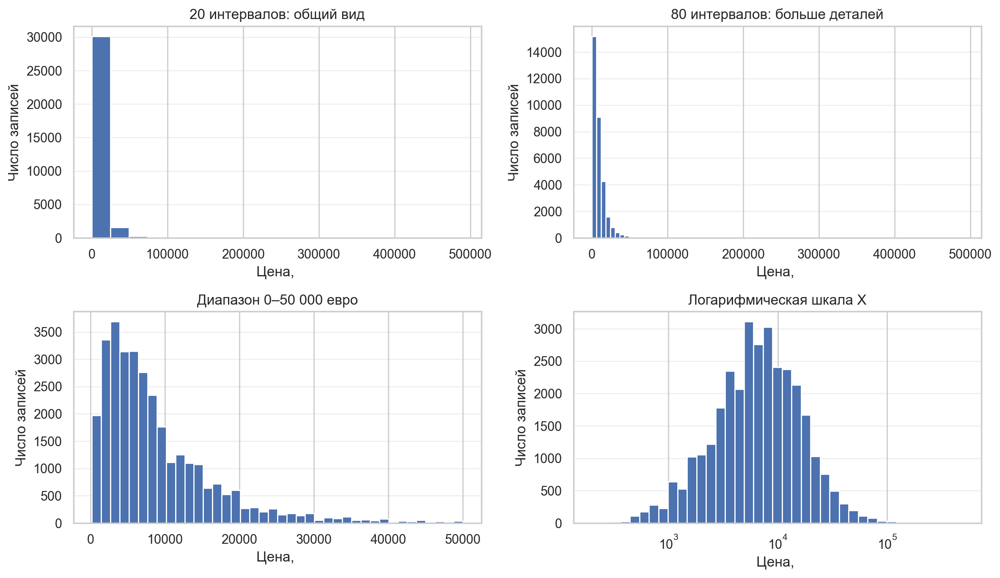

In [24]:
prices = df['Price'].dropna()
positive = prices[prices > 0]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

axes[0, 0].hist(prices, bins=20)
axes[0, 0].set_title('20 интервалов: общий вид')

axes[0, 1].hist(prices, bins=80)
axes[0, 1].set_title('80 интервалов: больше деталей')

axes[1, 0].hist(prices[prices.between(0, 50_000)], bins=40)
axes[1, 0].set_title('Диапазон 0–50 000 евро')

axes[1, 1].hist(
    positive, bins=np.geomspace(positive.min(), positive.max(), 40)
)
axes[1, 1].set_xscale('log')
axes[1, 1].set_title('Логарифмическая шкала X')

for ax in axes.flat:
    ax.set_xlabel('Цена, ')
    ax.set_ylabel('Число записей')
    ax.grid(axis='y', alpha=.3)

fig.tight_layout()
plt.show()

На логарифмической оси одинаковый шаг соответствует одинаковому отношению цен. Единицы остаются оригинальные. 

Такой масштаб помогает увидеть широкий диапазон; он не исправляет значения и не даёт основания их удалить.


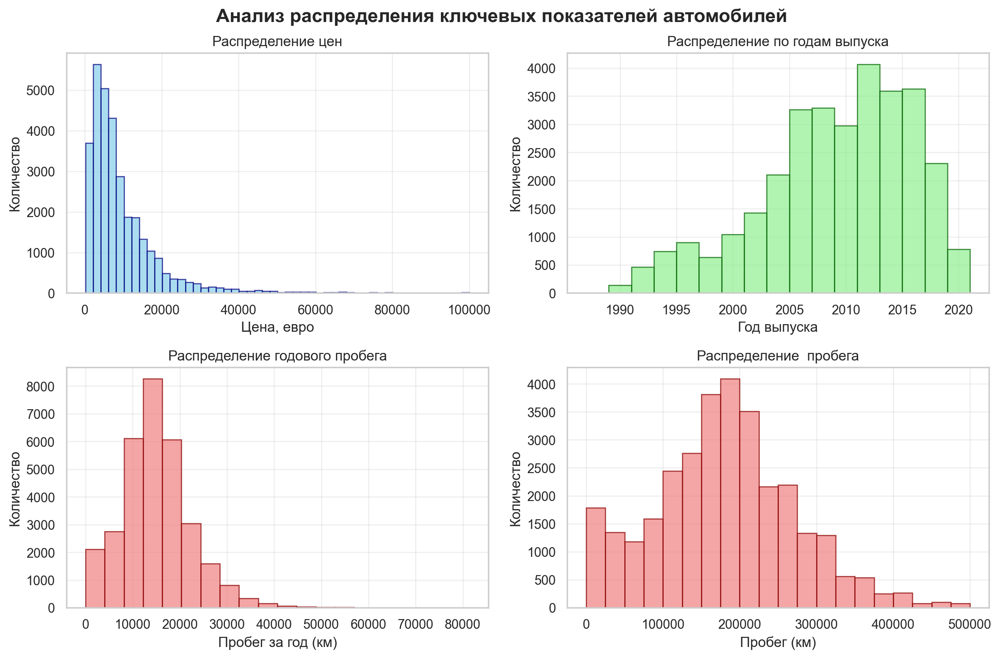

In [169]:
df_plot = df[
    df['Price'].between(0, 100_000)
    & df['km_year'].between(0, 100_000)
    & df['Distance'].between(0, 500_000)
    & df['Year'].between(1990, 2021)
].copy()
bins_years = range(1987, 2021+1, 2)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Анализ распределения ключевых показателей автомобилей', 
             fontsize=16, fontweight='bold', y=0.97)

# Гистограмма цен
axes[0,0].hist(df_plot['Price'], bins=50, color='skyblue', edgecolor='navy', alpha=0.7)
axes[0,0].set_title('Распределение цен')
axes[0,0].set_xlabel('Цена, евро')
axes[0,0].set_ylabel('Количество')
axes[0,0].grid(alpha=0.3)

# Гистограмма годов
axes[0,1].hist(df_plot['Year'], bins=bins_years, color='lightgreen', 
               edgecolor='darkgreen', alpha=0.7)
axes[0,1].set_title('Распределение по годам выпуска')
axes[0,1].set_xlabel('Год выпуска')
axes[0,1].set_ylabel('Количество')
axes[0,1].grid(alpha=0.3)

# Гистограмма пробега в год
km_filtered = df_plot['km_year']
axes[1,0].hist(km_filtered, bins=20, color='lightcoral', 
               edgecolor='darkred', alpha=0.7)
axes[1,0].set_title('Распределение годового пробега')
axes[1,0].set_xlabel('Пробег за год (км)')
axes[1,0].set_ylabel('Количество')
axes[1,0].grid(alpha=0.3)

# Гистограмма зависимости цены от пробега (hexbin)
km_ = df_plot['Distance']
axes[1,1].hist(km_, bins=20, color='lightcoral', 
               edgecolor='darkred', alpha=0.7)
axes[1,1].set_title('Распределение  пробега')
axes[1,1].set_xlabel('Пробег (км)')
axes[1,1].set_ylabel('Количество')
axes[1,1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


__Вывод__ нам нужны дополнительные фильтры наших записей 

```python
df_plot = df[
    df['Price'].between(0, 100_000)
    & df['km_year'].between(0, 100_000)
    & df['Distance'].between(0, 500_000)
    & df['Year'].between(1990, 2021)
].copy()

```

### [Seaborn](https://seaborn.pydata.org/examples/index.html): короткая запись статистических графиков


__Seaborn__ — это библиотека Python, построенная на основе Matplotlib и предназначенная для статистической визуализации. Она предлагает более высокий уровень абстракции, что упрощает создание сложных статистических графиков, таких как диаграммы рассеяния с регрессионными линиями, графики распределения и тепловые карты. Основные преимущества Seaborn включают:
* Упрощение создания сложных статистических графиков.
* Интеграция с Pandas DataFrame.
* Автоматическая настройка стилей и цветовых палитр.
* Встроенные функции для визуализации распределений и взаимосвязей.



https://seaborn.pydata.org/examples/index.html

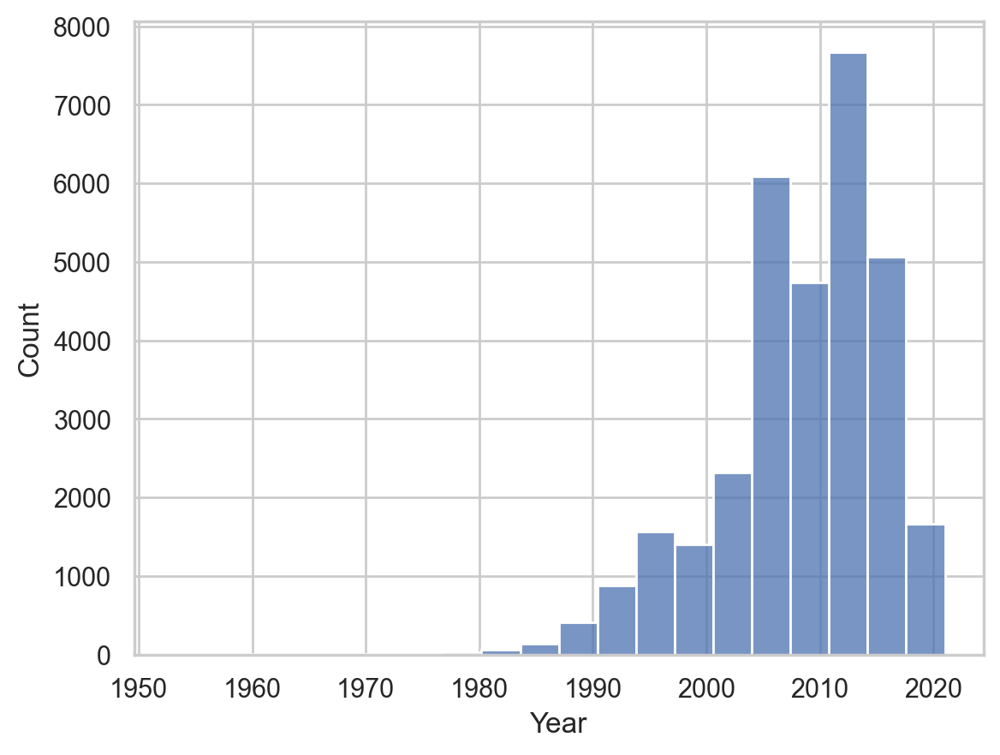

In [26]:
sns.histplot(data=df, x='Year', bins = 20);

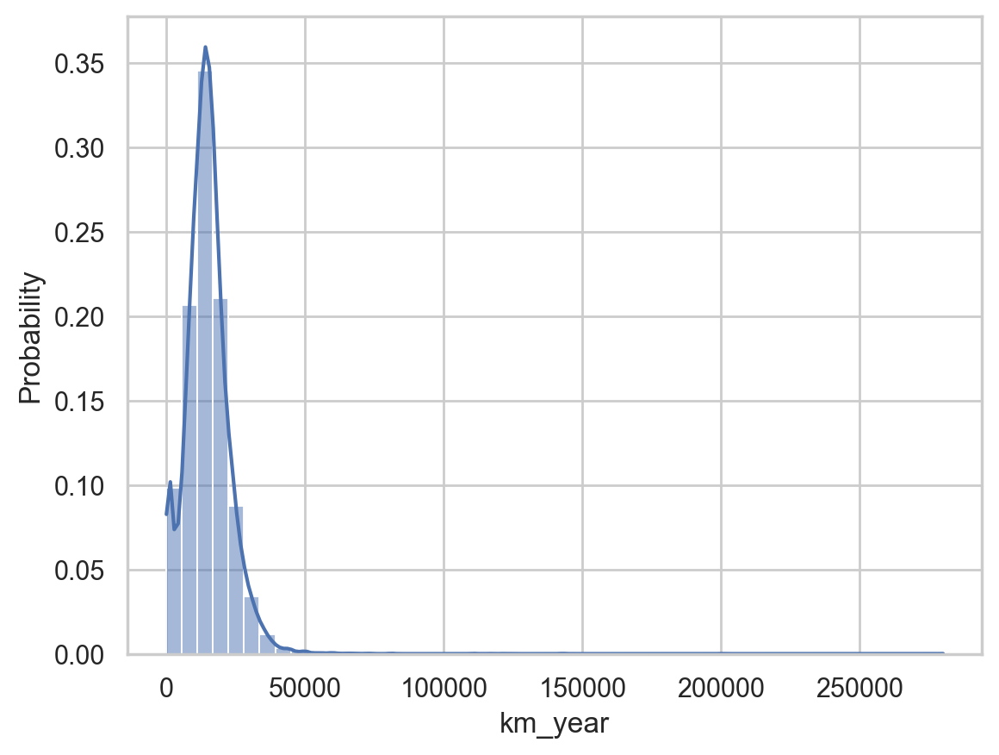

In [27]:
sns.histplot(df['km_year'], bins = 50, kde=True,  stat='probability');
plt.show()


Сраним нормальное распределение и лог-гистограмму цен.

### Представление распределний.

Хотя гистограмма это наверно основной способ представления случайной величины, не всегда удобно представлять случайную величину только гистограммой. 

Например, полезна визуализация __"BoxPlot"__

"BoxPlot" показывает Диапазон основной части значений данных, его медиану и диапазон в котом вероятно стоит ожидать данные.

Основной размах данных называется IQR, он показывает данные от тех, которые имеют вероятность 25\% (Q1) до тех, которые имеют вероятность 75\% (Q3). То есть IQR показывает диапазон, где лежит 50\% самых частых данных. Также "BoxPlot" имеет т.н. усы. При стандартном `whis=1.5` диапазон ожидаемых "нормально" данных в пределах [Q1 − 1.5·IQR, Q3 + 1.5·IQR]. 

Тогда точки снаружи — это крайне редкие или аномальные значени, например для редкого дорогого автомобиля.


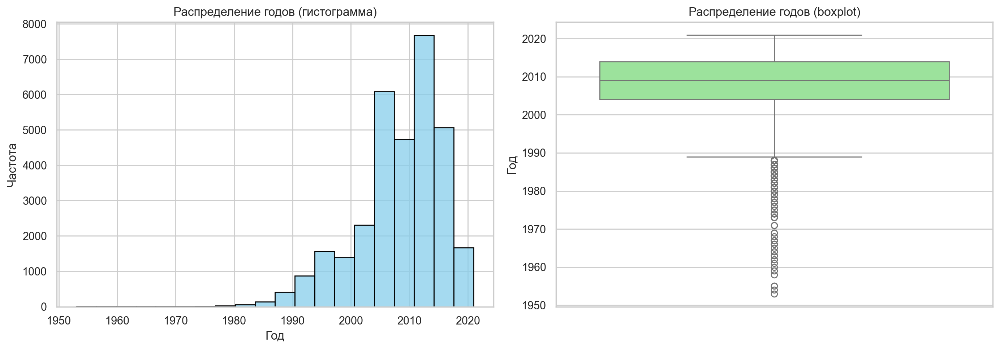

In [33]:
# Создаём фигуру с двумя подграфиками (1 строка, 2 столбца)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
sns.histplot(data=df, x='Year', bins=20, kde=False, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Распределение годов (гистограмма)')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Частота')

# Boxplot
sns.boxplot(data=df, y='Year', ax=axes[1], color='lightgreen')
axes[1].set_title('Распределение годов (boxplot)')
axes[1].set_ylabel('Год')
axes[1].set_xlabel('')

# Улучшаем отображение
plt.tight_layout()
plt.show()

Другие способы представления данных.

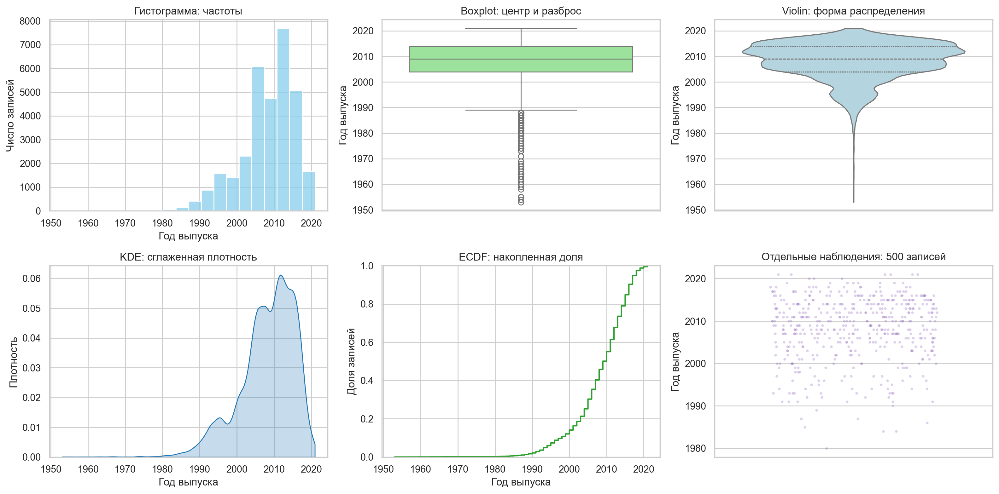

In [177]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
values = df['Year'].dropna()

# 1. Гистограмма — количество в интервалах
sns.histplot(x=values, bins=20, ax=axes[0, 0], color='skyblue')
axes[0, 0].set(title='Гистограмма: частоты',
               xlabel='Год выпуска', ylabel='Число записей')

# 2. Boxplot — медиана, квартили и крайние значения
sns.boxplot(y=values, ax=axes[0, 1], color='lightgreen')
axes[0, 1].set(title='Boxplot: центр и разброс', ylabel='Год выпуска')

# 3. Violin — форма распределения вместе с квартилями
sns.violinplot(y=values, inner='quartile', cut=0,
               ax=axes[0, 2], color='lightblue')
axes[0, 2].set(title='Violin: форма распределения', ylabel='Год выпуска')

# 4. KDE — сглаженная оценка плотности
sns.kdeplot(x=values, fill=True, cut=0,
            ax=axes[1, 0], color='tab:blue')
axes[1, 0].set(title='KDE: сглаженная плотность',
               xlabel='Год выпуска', ylabel='Плотность')

# 5. ECDF — доля записей со значением не выше заданного
sns.ecdfplot(x=values, ax=axes[1, 1], color='tab:green')
axes[1, 1].set(title='ECDF: накопленная доля',
               xlabel='Год выпуска', ylabel='Доля записей')

# 6. Точки — отдельные наблюдения с небольшим смещением
sample = values.sample(n=min(500, len(values)), random_state=42)
sns.stripplot(y=sample, jitter=.3, alpha=.3, size=3,
              ax=axes[1, 2], color='tab:purple')
axes[1, 2].set(title=f'Отдельные наблюдения: {len(sample)} записей',
               ylabel='Год выпуска')

fig.tight_layout()
plt.show()

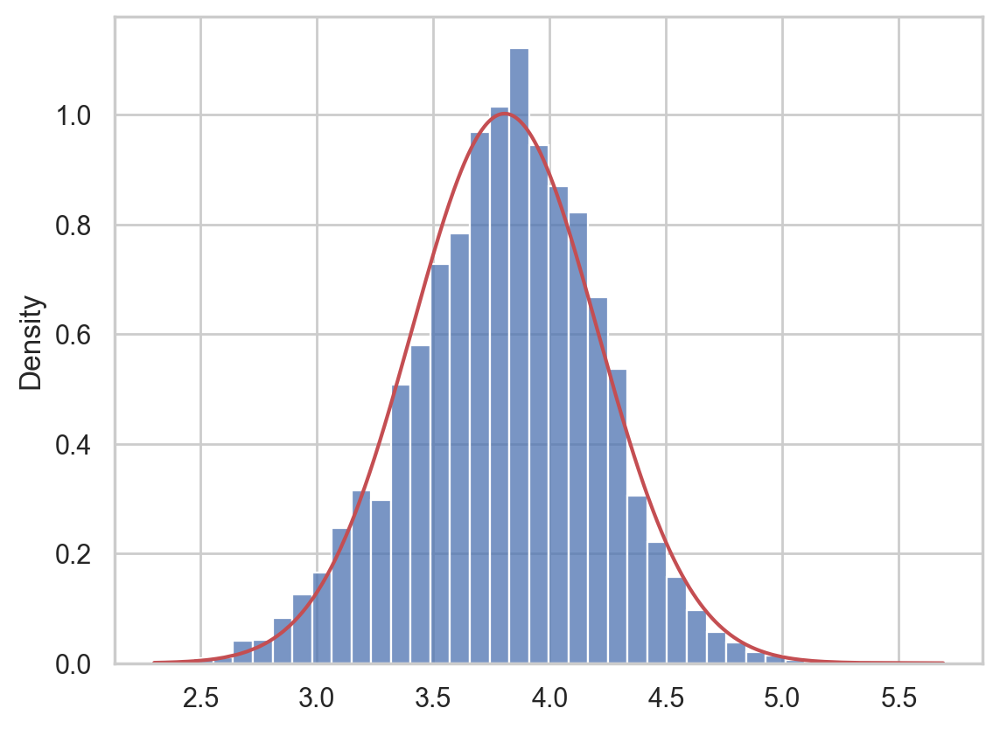

In [28]:
from scipy.stats import norm

x = np.sort(np.log10(df.loc[df['Price'] > 0, 'Price']))
sns.histplot(x=x, bins=40, stat='density')
plt.plot(x, norm.pdf(x, x.mean(), x.std()), 'r-')
plt.show()

C:\Users\Ronkin\AppData\Local\Temp\ipykernel_171740\1970953488.py:35: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.tight_layout()
C:\Users\Ronkin\AppData\Local\Temp\ipykernel_171740\1970953488.py:35: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.tight_layout()
C:\Users\Ronkin\anaconda3\envs\ts\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Ronkin\anaconda3\envs\ts\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


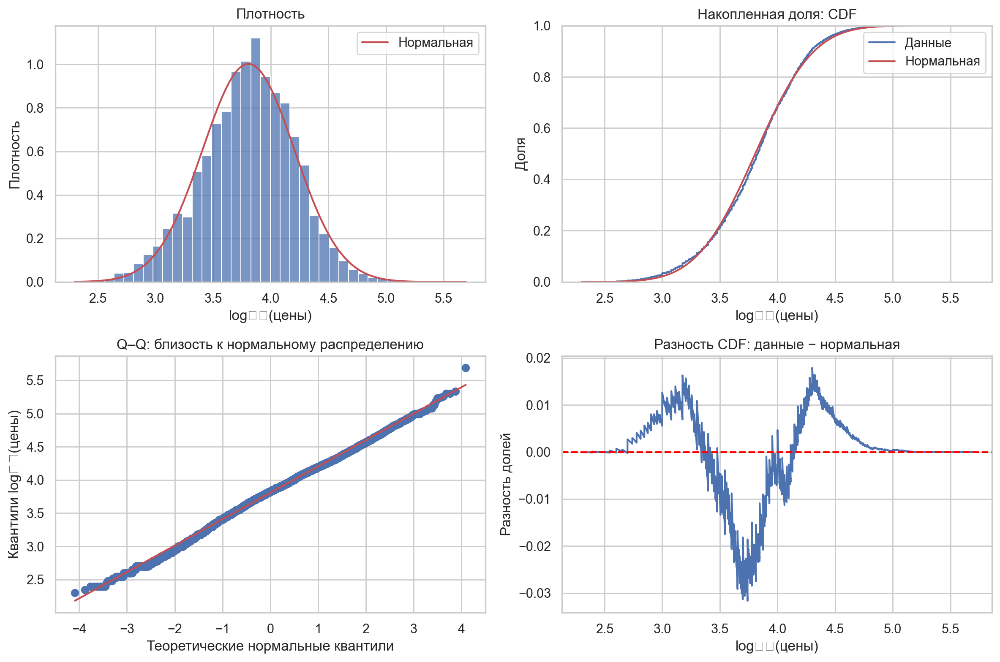

In [29]:
from scipy.stats import norm, probplot

x = np.sort(np.log10(df.loc[df['Price'] > 0, 'Price']))
mu, sigma = x.mean(), x.std()
grid = np.linspace(x.min(), x.max(), 500)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Гистограмма и нормальная плотность
sns.histplot(x=x, bins=40, stat='density', ax=axes[0, 0])
axes[0, 0].plot(grid, norm.pdf(grid, mu, sigma), 'r-', label='Нормальная')
axes[0, 0].set(title='Плотность', xlabel='log₁₀(цены)', ylabel='Плотность')
axes[0, 0].legend()

# 2. Эмпирическая и нормальная CDF
sns.ecdfplot(x=x, ax=axes[0, 1], label='Данные')
axes[0, 1].plot(grid, norm.cdf(grid, mu, sigma), 'r-', label='Нормальная')
axes[0, 1].set(title='Накопленная доля: CDF',
               xlabel='log₁₀(цены)', ylabel='Доля')
axes[0, 1].legend()

# 3. Q–Q: сравнение квантилей
probplot(x, dist='norm', plot=axes[1, 0])
axes[1, 0].set(title='Q–Q: близость к нормальному распределению',
               xlabel='Теоретические нормальные квантили',
               ylabel='Квантили log₁₀(цены)')

# 4. Отклонение эмпирической CDF от нормальной
ecdf = np.arange(1, len(x) + 1) / len(x)
axes[1, 1].plot(x, ecdf - norm.cdf(x, mu, sigma))
axes[1, 1].axhline(0, color='red', linestyle='--')
axes[1, 1].set(title='Разность CDF: данные − нормальная',
               xlabel='log₁₀(цены)', ylabel='Разность долей')

fig.tight_layout()
plt.show()

**Упражнение:** 
1. Проведите анализ разных способов представления выборки по каждой численной переменной и скорректируйте правила фильтрации данных (пороги фильтрации).

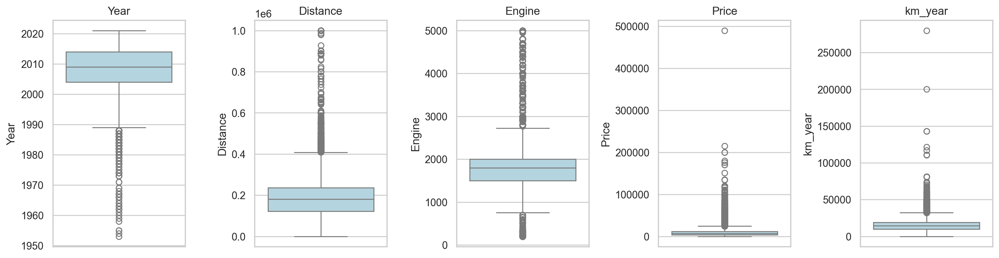

In [34]:
fig, axes = plt.subplots(1, len(num_columns), figsize=(3 * len(num_columns), 4))
for ax, col in zip(axes, num_columns):
    sns.boxplot(data=df, y=col, ax=ax, color='lightblue')
    ax.set_title(col)
fig.tight_layout()
plt.show()


## 6. Сравнение категорий и сегментов

На самом деле часто недостаточно только лишь проанализировать гисторагмму признака. Если мы ожидаем сложные (условно "xor") данные, то лучше анализировать совместное поведение нескольких признаков. То есть __условное распределние__

Для пар численная - категориальная переменная построим такие визуализации

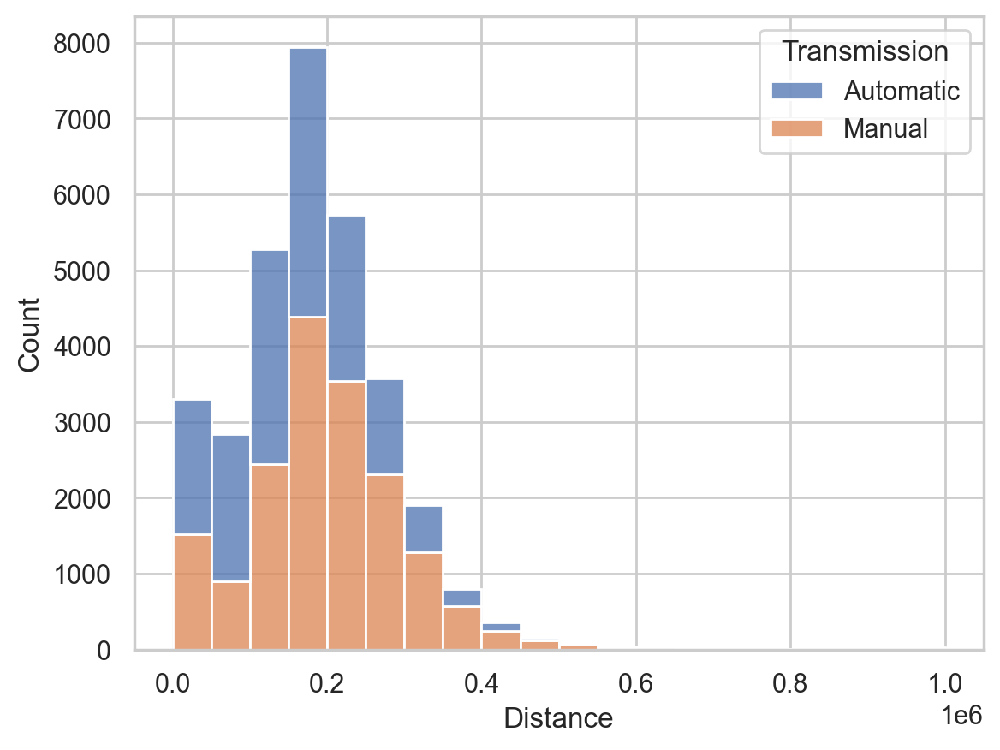

In [35]:
sns.histplot(data=df, 
             x='Distance',
             hue='Transmission', 
             multiple='stack', 
             bins = 20);
plt.show()

Перейдем к бокс-плотам, 
- они компактней,
- скрывают мелкие детали гистограммы, которые могут быть случайными,
- оставляют крупные признаки, которые вероятно и нужны на первом этапе.

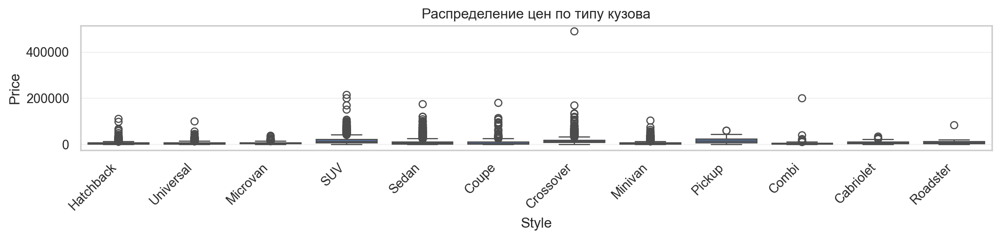

In [178]:
plt.figure(figsize= (12,3))

sns.boxplot(data=df, x='Style', y='Price')

plt.grid(axis='y', alpha=0.25)
plt.xticks(rotation=45, ha='right')  # ha='right' — чтобы подписи не "уезжали"
plt.title('Распределение цен по типу кузова')
plt.tight_layout()  # важно: предотвращает обрезание подписей
plt.show()

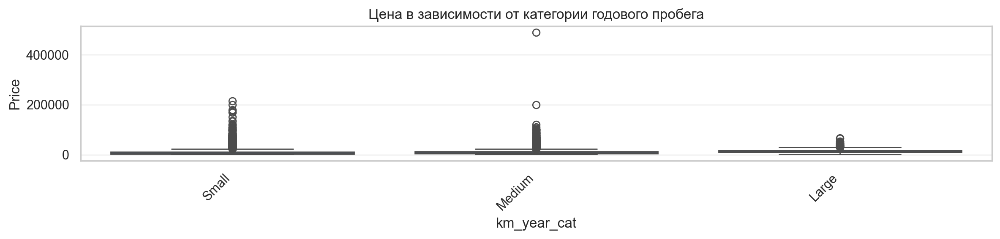

In [179]:
plt.figure(figsize= (12,3))

sns.boxplot(data=df, x='km_year_cat', y='Price');
plt.grid(axis='y', alpha=0.25)
plt.xticks(rotation=45, ha='right')  # ha='right' — чтобы подписи не "уезжали"
plt.title('Цена в зависимости от категории годового пробега')
plt.tight_layout()  # важно: предотвращает обрезание подписей
plt.show()



То есть возможный вывод, что для условно малого пробега не стоит фильтровать данные по ценам.

#### Категориальный график

`catplot` строит сетку панелей. Общая шкала помогает сравнить группы, но различия моделей и возраста всё ещё могут влиять на результат.


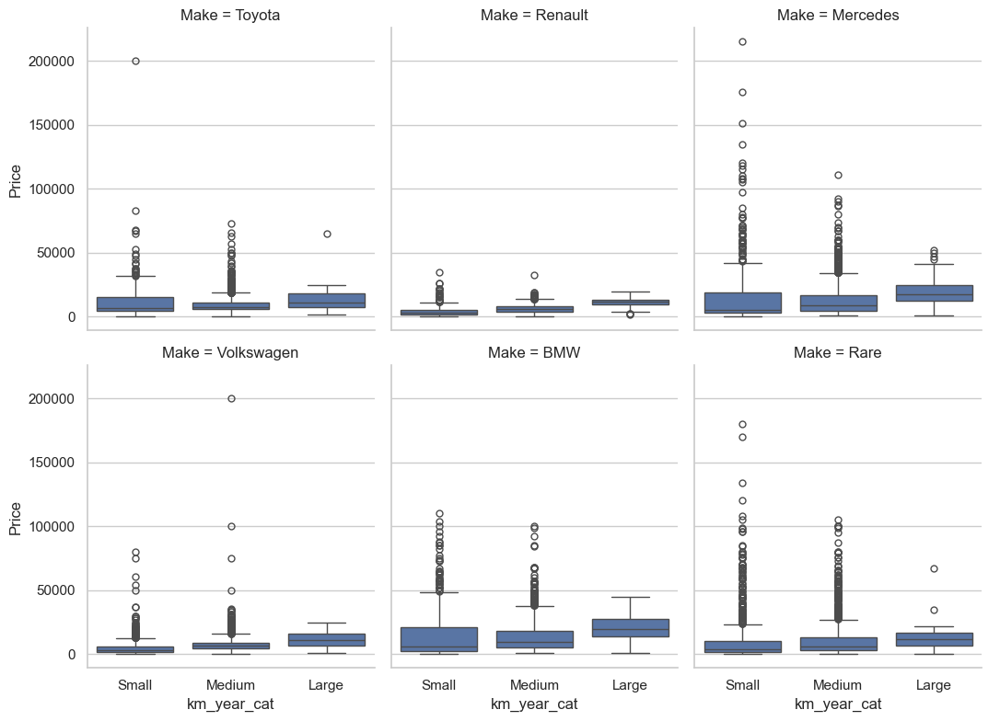

In [23]:
# Берём топ-6 брендов
top_makes = df['Make'].value_counts().head(6).index
df_top = df[df['Make'].isin(top_makes)]

sns.catplot(
    order=['Small', 'Medium', 'Large'],
    x='km_year_cat',
    y='Price',
    col='Make',
    data=df_top.dropna(subset=['km_year_cat', 'Price']),
    kind='box',
    col_wrap=3,
    height=4,
    aspect=0.9
)
plt.tight_layout()
plt.show()

### Упражение
1. скорректируйте выводы

## 5. Совместное поведение численных признаков 

Scatter показывает сочетания значений. При наложении точек используйте прозрачность, меньший размер маркера или `hexbin`. Цвет применяйте к небольшому числу категорий. Размер как ещё один канал может перегрузить график.


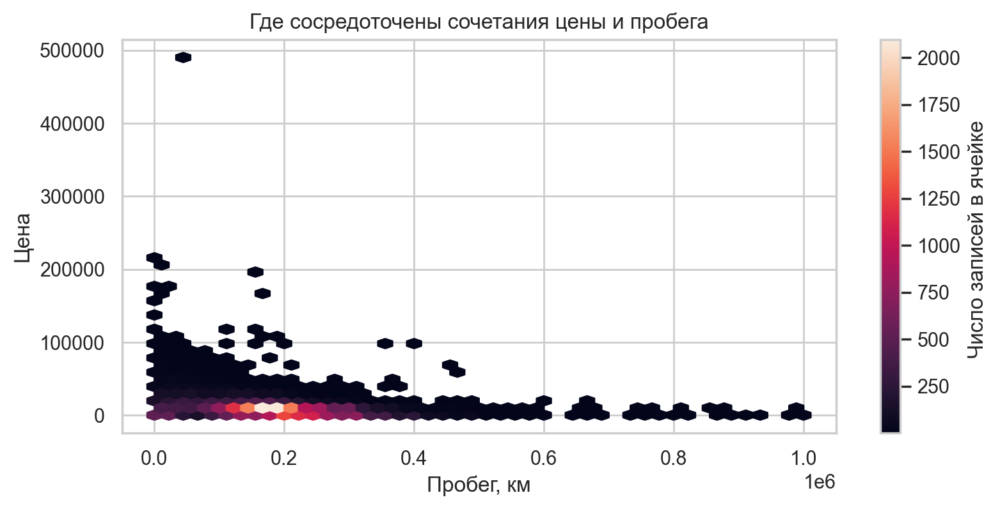

In [180]:
fig, ax = plt.subplots(figsize=(9, 4))
hb = ax.hexbin(df['Distance'], df['Price'], gridsize=45,  mincnt=1)
fig.colorbar(hb, ax=ax, label='Число записей в ячейке ')
ax.set(title='Где сосредоточены сочетания цены и пробега',
       xlabel='Пробег, км', ylabel='Цена')
plt.show()


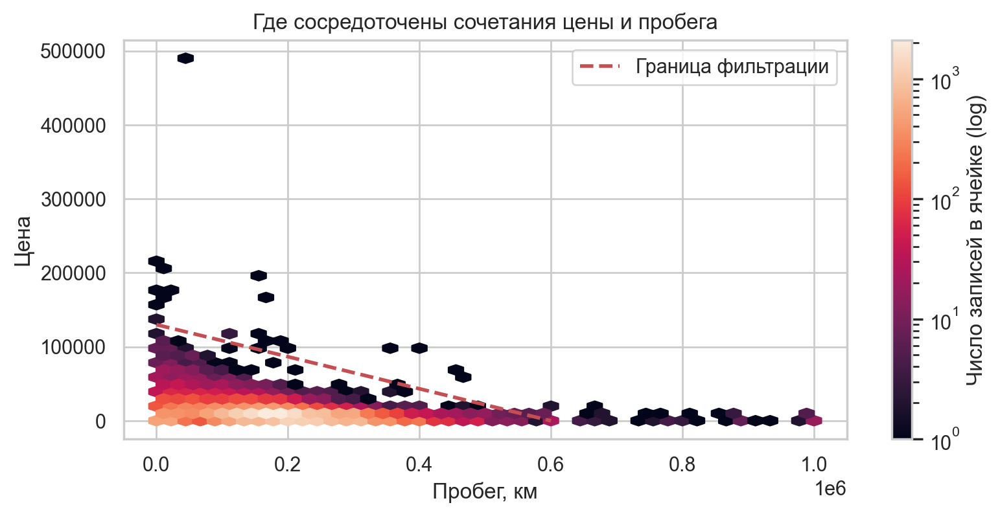

In [36]:
fig, ax = plt.subplots(figsize=(9, 4))
hb = ax.hexbin(df['Distance'], df['Price'], gridsize=45, bins='log', mincnt=1)
fig.colorbar(hb, ax=ax, label='Число записей в ячейке (log)')
ax.set(title='Где сосредоточены сочетания цены и пробега',
       xlabel='Пробег, км', ylabel='Цена')


ax.plot([0, 600_000], [130_000, 0], 'r--', linewidth=2,
        label='Граница фильтрации')
ax.legend()

plt.show()


### Упражение
1. Провидите фильтрацию по заданной границе 

## ## 5. Совместное поведение численных и категориальных признаков 

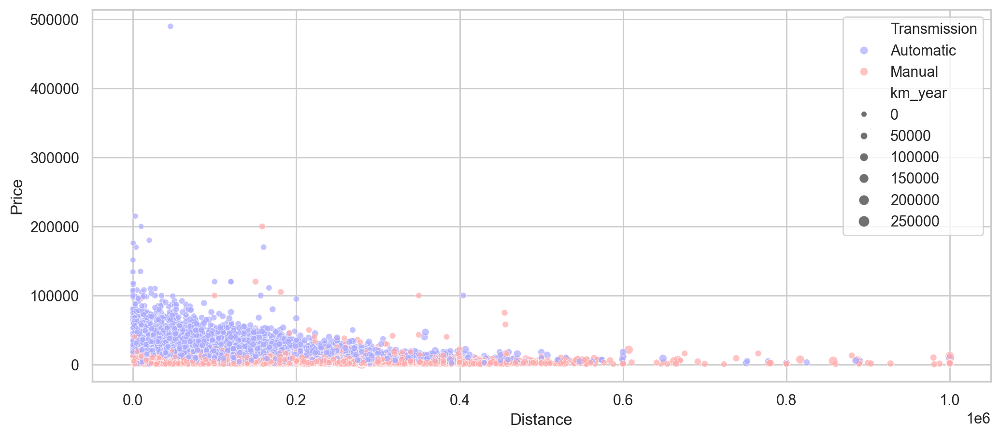

In [38]:
plt.figure(figsize=(12,5))
sns.scatterplot(    
    data=df,
    x="Distance", 
    y="Price",
    hue="Transmission", 
    size = "km_year", 
    alpha = 0.7,
    palette='bwr'
    );
plt.show()


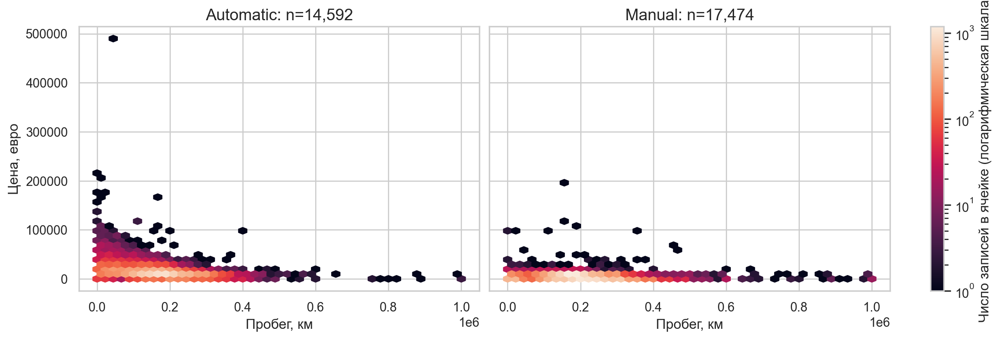

In [181]:
from matplotlib.colors import LogNorm

groups = df.groupby('Transmission')
fig, axes = plt.subplots(1, len(groups), figsize=(12, 4),
                         sharex=True, sharey=True, layout='constrained')

extent = (df['Distance'].min(), df['Distance'].max(),
          df['Price'].min(), df['Price'].max())

plots = []
for ax, (name, group) in zip(np.atleast_1d(axes), groups):
    hb = ax.hexbin(group['Distance'], group['Price'],
                  gridsize=45, extent=extent, mincnt=1, )
    plots.append(hb)
    ax.set_title(f'{name}: n={len(group):,}', fontsize=14)
    ax.set_xlabel('Пробег, км', fontsize=12)
    ax.tick_params(labelsize=11)

# Одинаковый цвет означает одинаковое количество записей
norm = LogNorm(vmin=1, vmax=max(2, max(h.get_array().max() for h in plots)))
for hb in plots:
    hb.set_norm(norm)

np.atleast_1d(axes)[0].set_ylabel('Цена, евро', fontsize=12)
fig.colorbar(plots[0], ax=np.atleast_1d(axes).tolist(),
             label='Число записей в ячейке (логарифмическая шкала)')
plt.show()

In [42]:
# g = sns.PairGrid(df.select_dtypes(include='number'))
# g.map_diag(sns.histplot)
# g.map_offdiag(sns.scatterplot)
# plt.show()

### Упражение
1. Уточните фильтрацию по А/М с ручной трансмиссией 

2. Подготовьте фильтрованный набор данных

# Интерактивная визуализация

__Plotly__ — это библиотека Python, предназначенная для интерактивной визуализации данных. Она позволяет создавать интерактивные графики, 3D-графики и географические карты, которые можно встраивать в веб-приложения и дашборды. Основные преимущества Plotly включают:
* Интерактивность: графики можно масштабировать, перемещать и настраивать с помощью мыши.
* Веб-ориентированность: графики можно встраивать в веб-приложения и дашборды.
* Поддержка различных типов графиков, включая 3D-графики и географические карты.
* Простота создания интерактивных дашбордов.

Примеры интерактивных визуализаций могут быть найдены [в галерее на официальном сайте](https://plotly.com/python/).


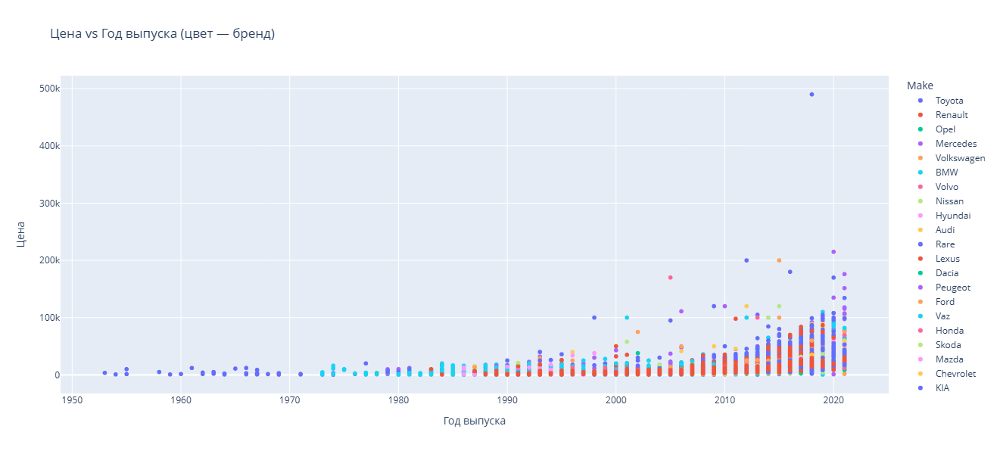

In [43]:
fig = px.scatter(
    df,
    x='Year',
    y='Price',
    color='Make',
    hover_data=['Model', 
                'Distance', 
                'Fuel_type', 
                df.index], 
    title='Цена vs Год выпуска (цвет — бренд)',
    labels={'Price': 'Цена ', 'Year': 'Год выпуска'}
)
fig.update_layout(height=600)
fig.show()

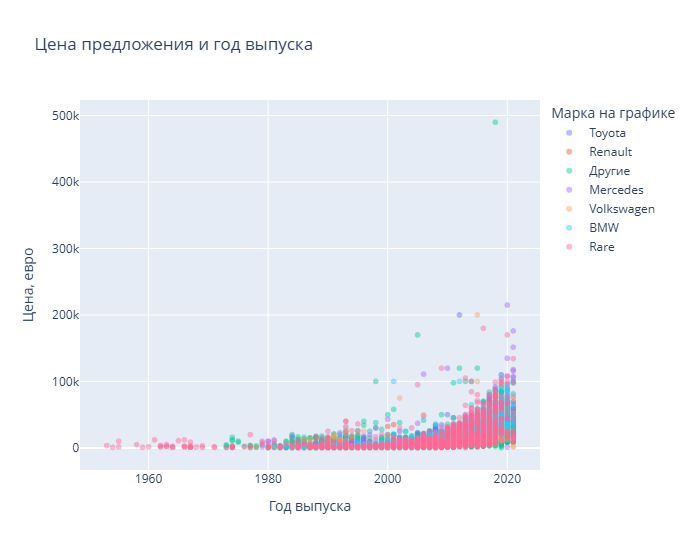

In [44]:
df_viz = df.copy()

top6 = df['Make'].value_counts().head(6).index
df_viz['Марка на графике'] = df_viz['Make'].where(df_viz['Make'].isin(top6),
                                                  'Другие')

fig = px.scatter(df_viz, x='Year', y='Price', color='Марка на графике',
    hover_data=['row_id', 
                'Make', 
                'Model', 
                'Distance', 
                'Fuel_type', 
                'Transmission'],
    opacity=.45, title='Цена предложения и год выпуска',
    labels={'Price': 'Цена, евро', 'Year': 'Год выпуска'})
fig.update_layout(height=550)
fig.show()


#### **Упражнение:** 
1. увеличьте область с подозрительными точками. Дополнительно отфильтруйте то, что кажется аномальным.


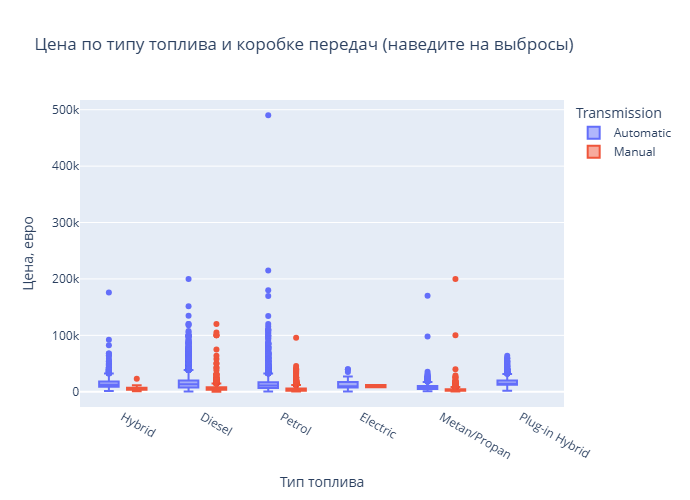

In [45]:
df_with_index = df.copy()
df_with_index['index_'] = df_with_index.index

fig = px.box(
    df_with_index,
    x='Fuel_type',
    y='Price',
    color='Transmission',
    hover_data=['row_id', 
                'Make', 
                'Model', 
                'Distance', 
                'Fuel_type', 
                'Transmission'],  # ← индекс и другая полезная инфа
    title='Цена по типу топлива и коробке передач (наведите на выбросы)',
    labels={'Price': 'Цена, евро', 'Fuel_type': 'Тип топлива'}
)
fig.update_layout(height=500)
fig.show()

## 8. Визуализация для презентации гипотез

Boxplot в Plotly помогает изучить крайние значения по типу топлива и трансмиссии. Критерий усов остаётся статистическим; стоимость сделки по этой диаграмме определить нельзя.


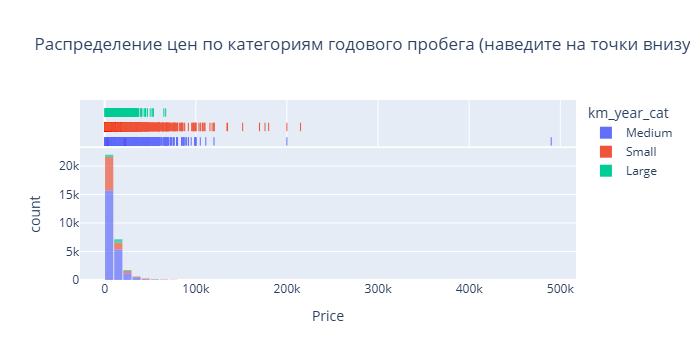

In [185]:
# Добавляем индекс как колонку
df_with_index = df.copy()
df_with_index['ID'] = df_with_index.index

fig = px.histogram(
    df_with_index,
    x='Price',
    color='km_year_cat',
    marginal='rug',  # ← rug показывает каждую точку
    hover_data=['row_id', 'Make', 'Model'],  # ← индекс и другая инфа
    opacity=0.7,
    nbins=50,
    title='Распределение цен по категориям годового пробега (наведите на точки внизу)'
)
fig.update_layout(bargap=0.1)
fig.show()

#### treemap и фильтры

Treemap показывает иерархию 

например «марка → модель»: площадь — число записей, цвет — средняя цена. 



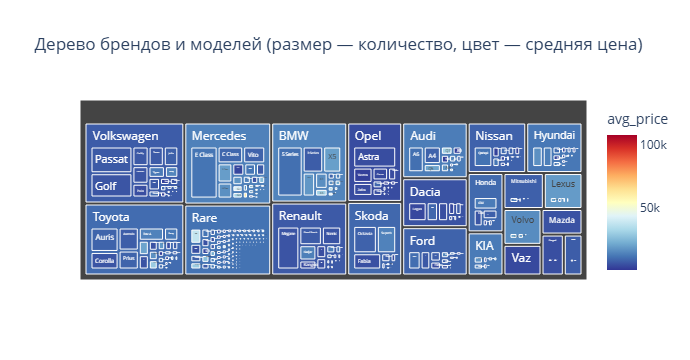

In [46]:
model_stats = df.groupby(['Make', 'Model']).agg(
    avg_price=('Price', 'mean'),
    count=('Price', 'size')
).reset_index()

fig = px.treemap(
    model_stats,
    path=['Make', 'Model'],
    values='count',
    color='avg_price',
    color_continuous_scale='RdYlBu_r',
    title='Дерево брендов и моделей (размер — количество, цвет — средняя цена)'
)
fig.show()

Treemap удоно использовать для обзора состава набора данных.  

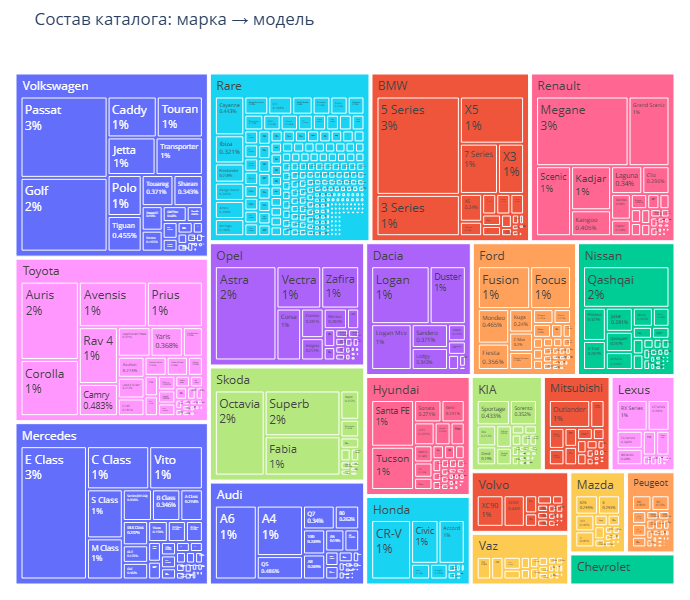

In [131]:
model_counts = df.groupby(['Make', 'Model']).size().reset_index(name='Count')

fig = px.treemap(
    model_counts,
    path=['Make', 'Model'],
    values='Count',
    color='Make',
    title='Состав каталога: марка → модель',
    labels={'Count': 'Число записей', 'Make': 'Марка', 'Model': 'Модель'}
)
fig.update_traces(textinfo='label+percent root')
fig.update_layout(height=600, margin=dict(t=50, l=10, r=10, b=10))
fig.show()

#### Фильтры для исследования конкретного сегмента

Виджеты работают в среде с поддержкой `ipywidgets` (например, JupyterLab). Для выбранного сегмента показываем объём выборки, медианную цену и точки. 


In [47]:
import pandas as pd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

# === 1. Подготовка данных ===
df_viz = df.copy()
df_viz['ID'] = df_viz['row_id']  # добавляем ID

# Уникальные категории для фильтров
makes = ['(Все)'] + sorted(df_viz['Make'].dropna().unique().tolist())
fuel_types = ['(Все)'] + sorted(df_viz['Fuel_type'].dropna().unique().tolist())
transmissions = ['(Все)'] + sorted(df_viz['Transmission'].dropna().unique().tolist())
km_cats = ['(Все)'] + sorted(df_viz['km_year_cat'].dropna().unique().tolist())

# === 2. Виджеты фильтров ===
make_widget = widgets.Dropdown(options=makes, value='(Все)', description='Бренд:')
fuel_widget = widgets.Dropdown(options=fuel_types, value='(Все)', description='Топливо:')
trans_widget = widgets.Dropdown(options=transmissions, value='(Все)', description='Коробка:')
km_widget = widgets.Dropdown(options=km_cats, value='(Все)', description='Пробег/год:')

# === 3. Функция обновления графика и таблицы ===
output = widgets.Output()

def update_plot(change=None):
    # Фильтрация
    filtered = df_viz.copy()
    
    if make_widget.value != '(Все)':
        filtered = filtered[filtered['Make'] == make_widget.value]
    if fuel_widget.value != '(Все)':
        filtered = filtered[filtered['Fuel_type'] == fuel_widget.value]
    if trans_widget.value != '(Все)':
        filtered = filtered[filtered['Transmission'] == trans_widget.value]
    if km_widget.value != '(Все)':
        filtered = filtered[filtered['km_year_cat'] == km_widget.value]
    
    # Очистка вывода
    with output:
        clear_output(wait=True)
        
        if filtered.empty:
            print("Нет данных по выбранным фильтрам.")
            return
        
        # Построение графика
        fig = px.scatter(
            filtered,
            x='Year',
            y='Price',
            color='Make',
            hover_data=['row_id', 'Model', 'Distance', 'Engine', 'Fuel_type', 'Transmission'],
            title=f'Записей: {len(filtered)}; медиана цены: {filtered["Price"].median():,.0f} евро',
            labels={'Price': 'Цена, евро', 'Year': 'Год выпуска'}
        )
        fig.update_layout(height=500, showlegend=False)
        fig.show()
        
        # Вывод таблицы (первые 10 записей)
        display(filtered[['row_id', 'Make', 'Model', 'Year', 'Price', 'Distance']].head(10))

# === 4. Привязка событий и запуск ===
make_widget.observe(update_plot, names='value')
fuel_widget.observe(update_plot, names='value')
trans_widget.observe(update_plot, names='value')
km_widget.observe(update_plot, names='value')

# Отображение интерфейса
controls = widgets.VBox([
    widgets.HTML("<h3>Фильтры для анализа автомобилей</h3>"),
    widgets.HBox([make_widget, fuel_widget]),
    widgets.HBox([trans_widget, km_widget])
])

display(controls)
update_plot()  # первый запуск
display(output)

Output()

### 9. Компактная BI-панель

Панель отвечает на несколько связанных вопросов на одном экране:
* сколько данных доступно,
* какие марки представлены и как распределены цены.



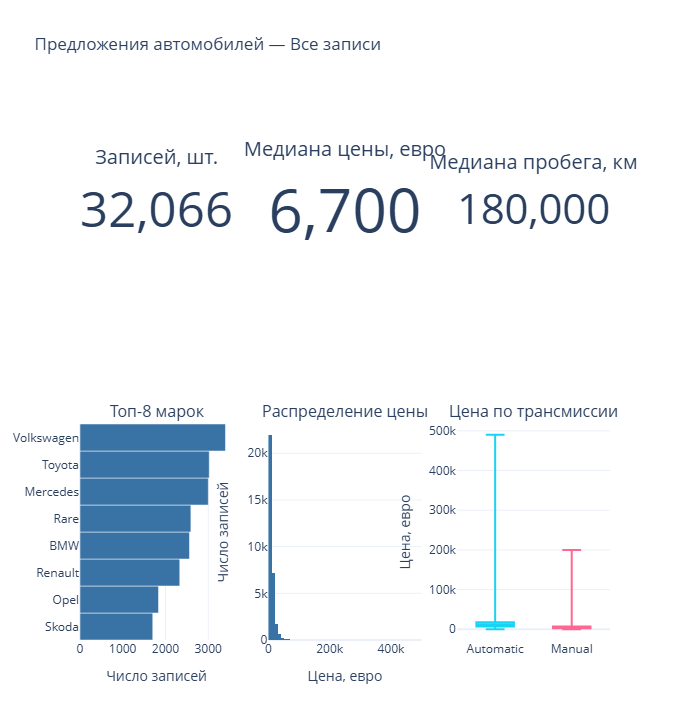

In [48]:
dashboard_df = df.copy()
DASHBOARD_FILTER = 'Все записи'
# Пример сегмента (раскомментируйте обе строки):
# dashboard_df = df[df['Transmission'] == 'Automatic'].copy()
# DASHBOARD_FILTER = 'Только Automatic'
if dashboard_df.empty:
    raise ValueError('Выбранный сегмент не содержит записей')

fig = make_subplots(rows=2, cols=3,
    specs=[[{'type': 'indicator'}] * 3,
           [{'type': 'xy'}, {'type': 'xy'}, {'type': 'xy'}]],
    subplot_titles=['', '', '', 'Топ-8 марок', 'Распределение цены', 'Цена по трансмиссии'],
    vertical_spacing=.2)
metrics = [('Записей, шт.', len(dashboard_df)),
           ('Медиана цены, евро', dashboard_df['Price'].median()),
           ('Медиана пробега, км', dashboard_df['Distance'].median())]
for column, (label, value) in enumerate(metrics, start=1):
    fig.add_trace(go.Indicator(mode='number', value=float(value),
        title={'text': label}, number={'valueformat': ',.0f'}), row=1, col=column)
brand_counts = dashboard_df['Make'].value_counts().head(8).sort_values()
fig.add_trace(go.Bar(x=brand_counts.values, y=brand_counts.index, orientation='h',
    marker_color='#3973a5'), row=2, col=1)
fig.add_trace(go.Histogram(x=dashboard_df['Price'], nbinsx=50, marker_color='#3973a5'), row=2, col=2)
for transmission, group in dashboard_df.groupby('Transmission'):
    fig.add_trace(go.Box(y=group['Price'], name=str(transmission), boxpoints=False), row=2, col=3)
fig.update_xaxes(title_text='Число записей', row=2, col=1)
fig.update_xaxes(title_text='Цена, евро', row=2, col=2)
fig.update_yaxes(title_text='Число записей', row=2, col=2)
fig.update_yaxes(title_text='Цена, евро', row=2, col=3)
fig.update_layout(height=720, showlegend=False,
    title=f'Предложения автомобилей — {DASHBOARD_FILTER}', template='plotly_white')
fig.show()


Дополнительно можно сохранять результаты.

In [134]:
# fig.write_html('cars_bi_dashboard.html', include_plotlyjs=True, full_html=True)
# fig.write_image('cars_bi_dashboard.pdf', width=1600, height=900)

## 10. Data Story: объясняем результат и предлагаем следующий шаг

**Data Story** — последовательный рассказ, который связывает вопрос аудитории, наблюдения в данных, их интерпретацию и предлагаемое действие.




### 10.4. График 1 — где сосредоточены записи


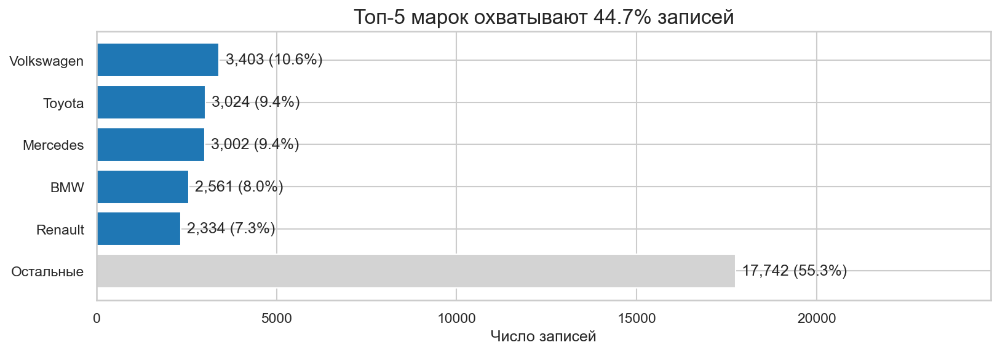

In [49]:
story_df = df.copy()
if 'Make_original' in story_df:
    story_df['Make'] = story_df['Make_original'].fillna(story_df['Make'])

counts = story_df['Make'].value_counts()
top5 = counts.drop(['Rare', 'Other'], errors='ignore').head(5)
share = 100 * top5.sum() / len(story_df)

plot_counts = top5.copy()
plot_counts['Остальные'] = len(story_df) - top5.sum()

fig, ax = plt.subplots(figsize=(11, 4), dpi=150)
bars = ax.barh(plot_counts.index, plot_counts.values,
               color=['tab:blue'] * len(top5) + ['lightgray'])
ax.invert_yaxis()
ax.bar_label(bars, labels=[
    f'{n:,} ({100*n/len(story_df):.1f}%)' for n in plot_counts
], padding=5)
ax.set_title(f'Топ-5 марок охватывают {share:.1f}% записей', fontsize=16)
ax.set_xlabel('Число записей', fontsize=12)
ax.set_xlim(0, plot_counts.max() * 1.4)
fig.tight_layout()
plt.show()

**Интерпретация:** определяем, какую часть каталога охватывают популярные марки и с каких сегментов начать проверку функций сервиса и где целевая аудитория.

## Слайд 2. Насколько различаются цены?

**Показываем:** медиану и разброс цен топ-5 марок.

**Интерпретация:** общей средней цены недостаточно — сервису нужны ценовые ориентиры по сегментам.

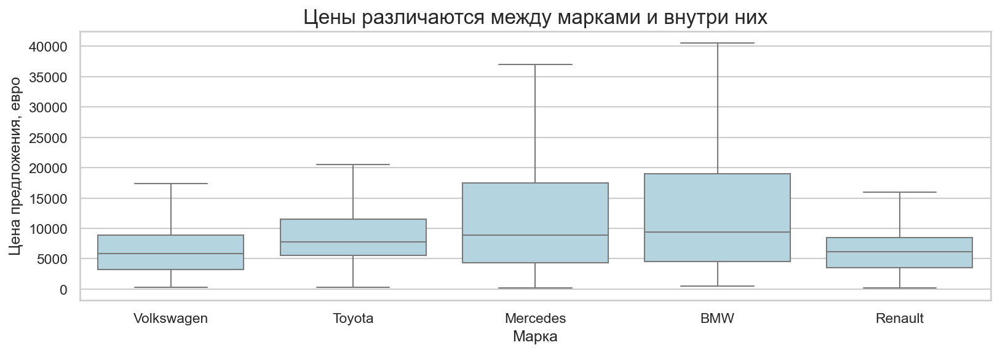

Крайние точки скрыты, но учтены при расчёте квартилей.


In [50]:
selected = story_df[
    story_df['Make'].isin(top5.index)
    & np.isfinite(story_df['Price'])
    & (story_df['Price'] > 0)
]

fig, ax = plt.subplots(figsize=(11, 4), dpi=150)
sns.boxplot(data=selected, x='Make', y='Price',
            order=top5.index, color='lightblue',
            showfliers=False, ax=ax)

ax.set_title('Цены различаются между марками и внутри них', fontsize=16)
ax.set_xlabel('Марка', fontsize=12)
ax.set_ylabel('Цена предложения, евро', fontsize=12)
fig.tight_layout()
plt.show()

print('Крайние точки скрыты, но учтены при расчёте квартилей.')

## Слайд 3. Что предлагаем для сервиса?

**Показываем:** цену и год выпуска отдельно для каждой марки.

**Интерпретация:** проверяем разброс цен внутри марки и года. Предлагаем сравнение похожих автомобилей и оценку цены с учётом модели, года и пробега.

**Следующий шаг:** проверить точность оценки на отложенных данных.

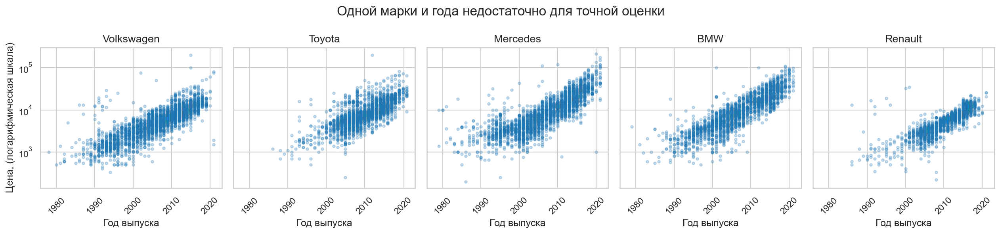

In [51]:
fig, axes = plt.subplots(1, len(top5), figsize=(17, 4),
                         sharex=True, sharey=True, dpi=150)

for ax, make in zip(np.atleast_1d(axes), top5.index):
    group = selected[selected['Make'] == make]
    ax.scatter(group['Year'], group['Price'],
               s=10, alpha=.25, color='tab:blue')
    ax.set_yscale('log')
    ax.set_title(make, fontsize=13)
    ax.set_xlabel('Год выпуска')
    ax.tick_params(axis='x', rotation=45)

np.atleast_1d(axes)[0].set_ylabel('Цена, (логарифмическая шкала)')
fig.suptitle('Одной марки и года недостаточно для точной оценки', fontsize=16)
fig.tight_layout()
plt.show()

Чем шире пятно или чем оно не равномерней, тем хуже.

**Вопрос:** стали ли ценовые группы более однородными после учёта годового пробега? Сравните медианы и ширину коробок.


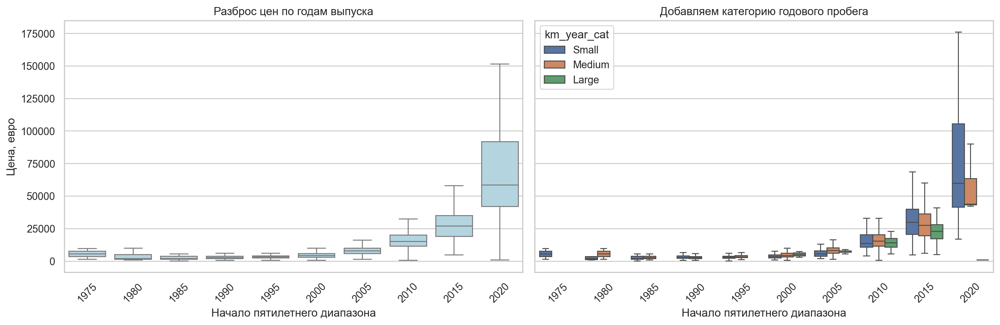

In [194]:
group = story_df[story_df['Make'] == 'Mercedes'].copy()
group['Годы выпуска'] = (group['Year'] // 5 * 5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

sns.boxplot(data=group, x='Годы выпуска', y='Price',
            showfliers=False, color='lightblue', ax=axes[0])
axes[0].set_title('Разброс цен по годам выпуска')

sns.boxplot(data=group, x='Годы выпуска', y='Price',
            hue='km_year_cat', showfliers=False, ax=axes[1])
axes[1].set_title('Добавляем категорию годового пробега')

for ax in axes:
    ax.set_xlabel('Начало пятилетнего диапазона')
    ax.set_ylabel('Цена, евро')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Упражнение.
1. Мы видим, по данным, что есть неостаток информации, попробуйте еще сделать "слайд" что еще нужно, чтобы уточнить закономерность цены от данных в нашей базе.

In [39]:
review.to_csv('cars_review_log.csv', index=False)
# Обоснованные исправления выполняйте в отдельной копии и описывайте в журнале.
# Исходные cars_processed.csv и cars_cleaned.csv здесь не перезаписываются.


## Документация

- [Matplotlib: Figure и Axes](https://matplotlib.org/stable/users/explain/quick_start.html)
- [Seaborn: сравнение категорий](https://seaborn.pydata.org/tutorial/categorical.html)
- [Seaborn: boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)
- [Plotly: treemap](https://plotly.com/python/treemaps/)
